# Projet : Prévision de l'inflation (États-Unis)

**Question :** le chômage et le taux directeur aident-ils à prévoir l'inflation d'un an sur l'autre ?

**Données :** fichier Excel mensuel (juillet 1954 à octobre 2026) avec trois séries : le taux d'inflation (variation annuelle de l'indice des prix, en %), le taux de chômage (%) et le taux directeur (%).

## Objectifs
1. identifier le **type de problème** et justifier ce choix ;
2. charger, nettoyer et vérifier les données ;
3. explorer avec des **requêtes** et des **graphiques** ;
4. construire des **retards** et un découpage chronologique sans fuite de données ;
5. comparer trois modèles : **dernière valeur** (référence), **Ridge**, **gradient boosting** ;
6. mesurer l'erreur (RMSE) sur un **horizon de 12 mois** ;
7. analyser l'**importance des variables** pour répondre à la question ;
8. signaler les **limites**, en particulier le biais d'anticipation (*look-ahead bias*).

## 1. De quel type de problème s'agit-il ?
Nous avons trois séries mensuelles. On veut prédire un **nombre réel** (l'inflation dans 12 mois) à partir d'informations connues aujourd'hui : c'est de l'**apprentissage supervisé, plus précisément une régression sur séries temporelles**.

- **Cible** : l'inflation 12 mois plus tard.
- **Variables d'entrée** : l'inflation, le chômage et le taux directeur d'aujourd'hui et de quelques mois passés (les « retards »).
- **Horizon** : 12 mois. Pour chaque mois *t*, on prédit l'inflation du mois *t + 12*.
- **Ordre du temps** : on ne mélange jamais les lignes. Le passé sert à apprendre, le futur à tester.

**Comment répondre à la question ?** On compare un modèle qui n'utilise que l'inflation passée à des modèles qui ajoutent le chômage et/ou le taux directeur. Si l'erreur baisse nettement, ces variables aident. Sinon, elles n'apportent rien de plus.

## 2. Chargement des données

In [4]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

def rmse(vrai, prevu):
    return np.sqrt(mean_squared_error(vrai, prevu))

In [6]:
# Chargement du fichier Excel
# Dans Google Colab : une fenêtre s'ouvre, choisis le fichier "Base_de_donne_projet_inflation.xlsx"
try:
    from google.colab import files
    televerse = files.upload()
    FICHIER = list(televerse.keys())[0]
except ImportError:
    FICHIER = "Base_de_donne_projet_inflation.xlsx"   # si tu exécutes en local

brut = pd.read_excel(FICHIER)
print("Dimensions brutes :", brut.shape)
brut.head()

Saving Base de donne projet inflation.xlsx to Base de donne projet inflation.xlsx
Dimensions brutes : (868, 4)


,Période,Taux d’inflation (%),Taux de chômage (%),Taux directeur (%)
0,1954-07,0.26,5.8,0.80
1,1954-08,0.00,6.0,1.22
2,1954-09,-0.30,6.1,1.07
3,1954-10,-0.85,5.7,0.85
4,1954-11,-0.26,5.3,0.83


## 3. Nettoyage et vérifications
Étapes :
- transformer la colonne « Période » (texte comme `1954-07`) en vraie **date** ;
- renommer les colonnes avec des noms courts : `infl`, `chom`, `taux` ;
- vérifier qu'il n'y a **aucun mois manquant** dans le calendrier (alignement des dates) ;
- traiter les valeurs manquantes.

**Remarque sur l'inflation.** La consigne demande de calculer la variation annuelle de l'indice des prix. Ici, le fichier contient **déjà** cette variation annuelle en pourcentage, soit : (indice du mois ÷ indice du même mois un an plus tôt − 1) × 100. Cette étape est donc déjà faite dans la base.

In [7]:
df = brut.copy()
df.columns = ["Periode", "infl", "chom", "taux"]
df["Date"] = pd.to_datetime(df["Periode"], format="%Y-%m")
df = df.set_index("Date").sort_index()

# Alignement : tous les mois entre le début et la fin sont-ils présents ?
mois_attendus = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Mois manquants dans le calendrier :", len(mois_attendus.difference(df.index)))
print("Période couverte :", df.index.min().strftime("%Y-%m"), "->", df.index.max().strftime("%Y-%m"))

# Valeurs manquantes
print("\nValeurs manquantes par colonne :")
print(df[["infl", "chom", "taux"]].isna().sum())
print("\nLignes concernées :")
print(df[df.isna().any(axis=1)][["infl", "chom", "taux"]])

Mois manquants dans le calendrier : 0
Période couverte : 1954-07 -> 2026-10

Valeurs manquantes par colonne :
infl    2
chom    1
taux    0
dtype: int64

Lignes concernées :
            infl  chom  taux
Date                        
2025-10-01   NaN   NaN  4.09
2026-10-01   NaN   4.1  3.88


In [8]:
# Un seul mois isolé manque au milieu de la série (2025-10) : on l'interpole linéairement.
# Le dernier mois (2026-10) n'a pas encore d'inflation publiée : on le laisse vide (limit_area="inside").
for c in ["infl", "chom"]:
    df[c] = df[c].interpolate(limit_area="inside")

print("Valeurs manquantes restantes :")
print(df[["infl", "chom", "taux"]].isna().sum())
df[["infl", "chom", "taux"]].tail(4)

Valeurs manquantes restantes :
infl    1
chom    0
taux    0
dtype: int64


,infl,chom,taux
Date,,,
2026-07-01,3.30,4.1,3.63
2026-08-01,3.35,4.1,3.63
2026-09-01,3.72,4.2,3.75
2026-10-01,NaN,4.1,3.88


In [9]:
# OPTIONNEL : vérifier la variation annuelle en la recalculant depuis l'indice des prix (FRED, CPIAUCSL).
# Cette cellule demande internet. Si elle échoue, ce n'est pas grave : le reste du notebook fonctionne sans elle.
try:
    URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL"
    ipc = pd.read_csv(URL, index_col=0, parse_dates=True).iloc[:, 0].astype(float)
    infl_recalculee = ipc.pct_change(12) * 100          # variation annuelle en %
    comparaison = pd.concat([df["infl"], infl_recalculee.rename("infl_FRED")], axis=1).dropna()
    ecart = (comparaison["infl"] - comparaison["infl_FRED"]).abs()
    print("Mois comparés :", len(comparaison))
    print("Écart absolu moyen entre le fichier et le calcul FRED :", round(ecart.mean(), 3), "point de %")
    print("Écart maximal :", round(ecart.max(), 3), "point de %")
except Exception as erreur:
    print("Cellule ignorée (pas d'accès à FRED) :", type(erreur).__name__)

Mois comparés : 867
Écart absolu moyen entre le fichier et le calcul FRED : 0.003 point de %
Écart maximal : 0.131 point de %


/tmp/ipykernel_435/360777887.py:6: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  infl_recalculee = ipc.pct_change(12) * 100          # variation annuelle en %


## 4. Première exploration

In [10]:
df[["infl", "chom", "taux"]].info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 868 entries, 1954-07-01 to 2026-10-01
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   infl    867 non-null    float64
 1   chom    868 non-null    float64
 2   taux    868 non-null    float64
dtypes: float64(3)
memory usage: 59.4 KB


In [11]:
# Statistiques descriptives
df[["infl", "chom", "taux"]].describe().round(2)

,infl,chom,taux
count,867.00,868.00,868.00
mean,3.57,5.78,4.59
std,2.76,1.67,3.52
min,-1.96,3.40,0.05
25%,1.73,4.40,1.94
50%,2.94,5.50,4.24
75%,4.37,6.82,6.10
max,14.59,14.80,19.10


**Lecture.** L'inflation moyenne est d'environ 3,6 % (médiane 2,9 %), avec un maximum de 14,6 %. Le chômage varie de 3,4 % à 14,8 % et le taux directeur de 0,05 % à 19,1 %. Les maxima sont très loin des médianes : l'histoire contient des périodes extrêmes (années 1970-1980, 2020). Seule l'inflation d'octobre 2026 manque encore : on la laisse vide.

## 5. Requêtes sur les données
Les requêtes servent à poser des questions précises au tableau avec `query`, le filtrage booléen et `groupby`.

In [12]:
# Q1 : Quand chaque série a-t-elle atteint son maximum et son minimum ?
for col, nom in [("infl", "Inflation"), ("chom", "Chômage"), ("taux", "Taux directeur")]:
    print(f"{nom:15s} max {df[col].max():5.2f} % en {df[col].idxmax():%Y-%m}  |  min {df[col].min():5.2f} % en {df[col].idxmin():%Y-%m}")

Inflation       max 14.59 % en 1980-03  |  min -1.96 % en 2009-07
Chômage         max 14.80 % en 2020-04  |  min  3.40 % en 1968-09
Taux directeur  max 19.10 % en 1981-06  |  min  0.05 % en 2020-04


In [13]:
# Q2 : Quelles années ont eu des mois avec une inflation supérieure à 8 % ? (nombre de mois par année)
haute = df.query("infl > 8")
print("Nombre total de mois :", len(haute))
haute.groupby(haute.index.year).size().rename("mois > 8 %").to_frame()

Nombre total de mois : 71


,mois > 8 %
Date,
1973,3
1974,12
1975,8
1978,4
1979,12
1980,12
1981,12
1982,1
2022,7


In [14]:
# Q3 : Quelles années ont eu un chômage supérieur à 10 % ?
chom_haut = df.query("chom > 10")
chom_haut.groupby(chom_haut.index.year).size().rename("mois > 10 %").to_frame()

,mois > 10 %
Date,
1982,4
1983,6
2020,4


In [15]:
# Q4 : Quand le taux directeur a-t-il dépassé 10 % ?
taux_haut = df.query("taux > 10")
print("Nombre de mois :", len(taux_haut), "| du", taux_haut.index.min().strftime("%Y-%m"), "au", taux_haut.index.max().strftime("%Y-%m"))

Nombre de mois : 61 | du 1973-07 au 1984-09


In [16]:
# Q5 : Combien de mois d'inflation négative (déflation) et quand ?
defl = df.query("infl < 0")
print("Nombre de mois :", len(defl))
defl.groupby(defl.index.year).size().rename("mois < 0").to_frame()

Nombre de mois : 26


,mois < 0
Date,
1954,4
1955,8
2008,1
2009,9
2015,4


In [17]:
# Q6 : Moyennes par décennie
df["Decennie"] = (df.index.year // 10 * 10).astype(str) + "s"
par_decennie = df.groupby("Decennie")[["infl", "chom", "taux"]].mean().round(2)
par_decennie

,infl,chom,taux
Decennie,,,
1950s,1.48,5.07,2.36
1960s,2.33,4.78,4.18
1970s,7.09,6.22,7.10
1980s,5.56,7.27,9.97
1990s,3.01,5.76,5.15
2000s,2.57,5.54,2.96
2010s,1.77,6.22,0.61
2020s,3.89,4.76,2.87


In [18]:
# Q7 : Quelles sont les plus fortes hausses de l'inflation en 12 mois ? (accélérations brutales)
df["hausse_12m"] = df["infl"].diff(12)
df.nlargest(5, "hausse_12m")[["infl", "hausse_12m"]].round(2)

,infl,hausse_12m
Date,,
2022-02-01,7.94,6.27
2022-01-01,7.56,6.19
1974-02-01,10.00,6.14
1974-01-01,9.60,5.96
2022-03-01,8.57,5.90


In [19]:
# Q8 : Corrélations entre les trois séries, et avec l'inflation observée 12 mois plus tard
df["infl_dans_12m"] = df["infl"].shift(-12)
corr = df[["infl", "chom", "taux", "infl_dans_12m"]].corr().round(2)
corr

,infl,chom,taux,infl_dans_12m
infl,1.00,0.10,0.71,0.73
chom,0.10,1.00,0.07,0.05
taux,0.71,0.07,1.00,0.57
infl_dans_12m,0.73,0.05,0.57,1.00


In [20]:
# Q9 : mêmes corrélations, mais seulement depuis 1990 (on exclut le régime des années 1970-1980)
recent = df.loc["1990":, ["infl", "chom", "taux", "infl_dans_12m"]].corr().round(2)
recent

,infl,chom,taux,infl_dans_12m
infl,1.00,-0.33,0.35,0.29
chom,-0.33,1.00,-0.45,-0.03
taux,0.35,-0.45,1.00,0.10
infl_dans_12m,0.29,-0.03,0.10,1.00


**Lecture.**
- Les mois d'inflation au-dessus de 8 % se concentrent entre 1973 et 1982, puis en 2022. Le chômage dépasse 10 % seulement en 1982-1983 et en 2020. Le taux directeur dépasse 10 % pendant 61 mois, entre 1973 et 1984.
- Les décennies 1970 et 1980 sont les plus inflationnistes (7,1 % et 5,6 % en moyenne) et ont les taux les plus élevés. Les années 2010 sont calmes (inflation 1,8 %, taux 0,6 %), et les années 2020 voient l'inflation remonter (3,9 %).
- Les plus fortes accélérations en 12 mois ont eu lieu en 1974 et début 2022 : des chocs rapides, donc difficiles à prévoir.
- **Corrélation avec l'inflation dans 12 mois** : 0,73 pour l'inflation actuelle, 0,57 pour le taux directeur, seulement 0,05 pour le chômage. Mais **depuis 1990** (Q9), la corrélation du taux directeur tombe à 0,10 et celle du chômage devient proche de zéro (-0,03). Le lien du taux directeur vient donc surtout du régime des années 1970-1980.

## 6. Visualisation des données

### 6.1 Les trois séries dans le temps

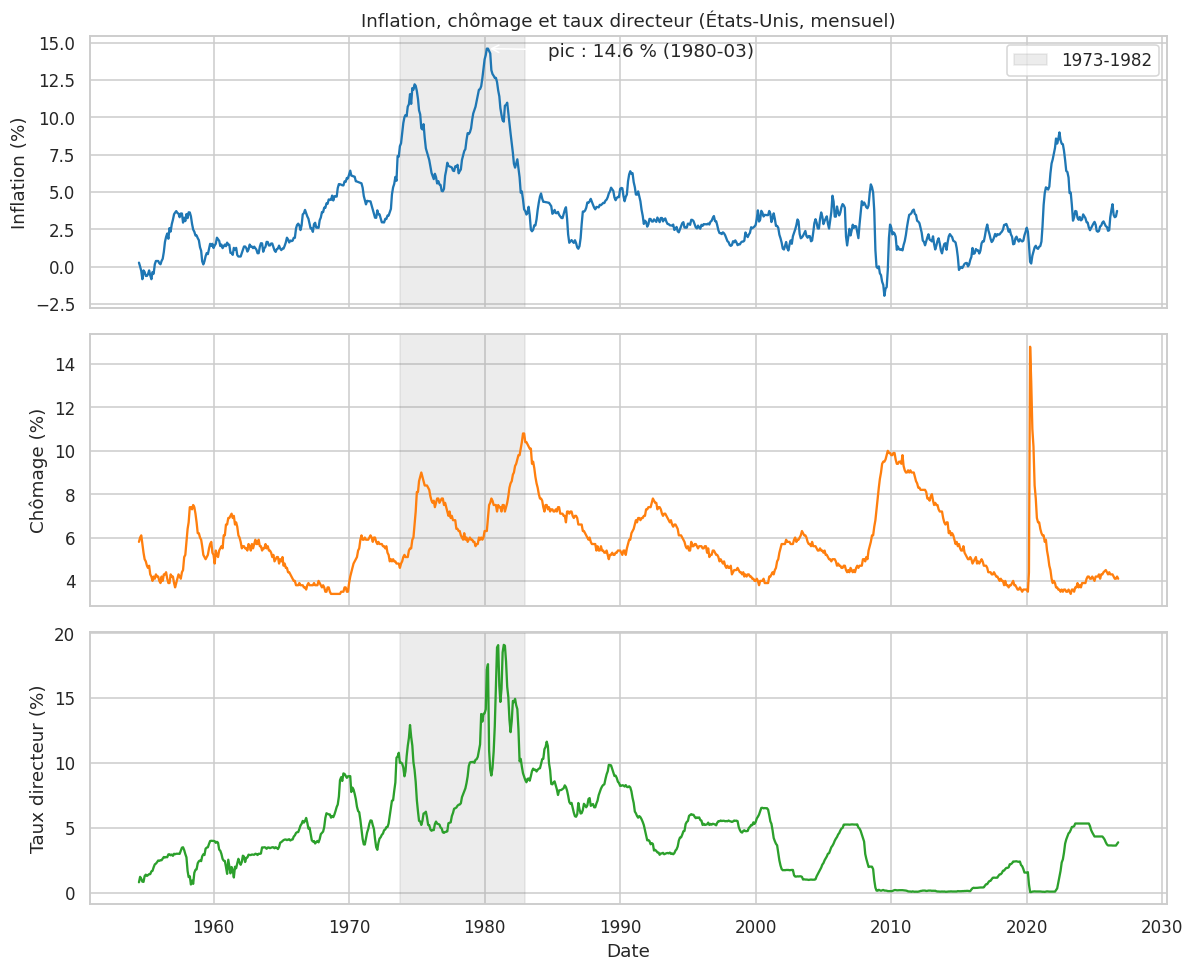

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
series = [("infl", "Inflation (%)", "tab:blue"),
          ("chom", "Chômage (%)", "tab:orange"),
          ("taux", "Taux directeur (%)", "tab:green")]
for ax, (col, titre, couleur) in zip(axes, series):
    ax.plot(df.index, df[col], color=couleur, linewidth=1.5)
    ax.axvspan(pd.Timestamp("1973-10-01"), pd.Timestamp("1982-12-31"), color="grey", alpha=0.15,
               label="1973-1982" if col == "infl" else None)
    ax.set_ylabel(titre)
i = df["infl"].idxmax()
axes[0].annotate(f"pic : {df.loc[i, 'infl']:.1f} % ({i:%Y-%m})", (i, df.loc[i, "infl"]),
                 xytext=(40, -5), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
axes[0].legend(loc="upper right")
axes[0].set_title("Inflation, chômage et taux directeur (États-Unis, mensuel)")
axes[2].set_xlabel("Date")
plt.tight_layout()
plt.show()

**Lecture.** Dans les années 1970-1980 (zone grise), l'inflation et le taux directeur montent ensemble, puis redescendent ensemble : la banque centrale monte ses taux **en réaction** à l'inflation. Le chômage, lui, évolue autrement : il monte lentement en 1980-1983, puis explose en 2020 (14,8 %) avant de retomber vite. Début 2021, le taux directeur est encore proche de zéro alors que l'inflation commence à accélérer : une raison de douter que ces variables permettent de prévoir un choc.

### 6.2 Moyennes par décennie

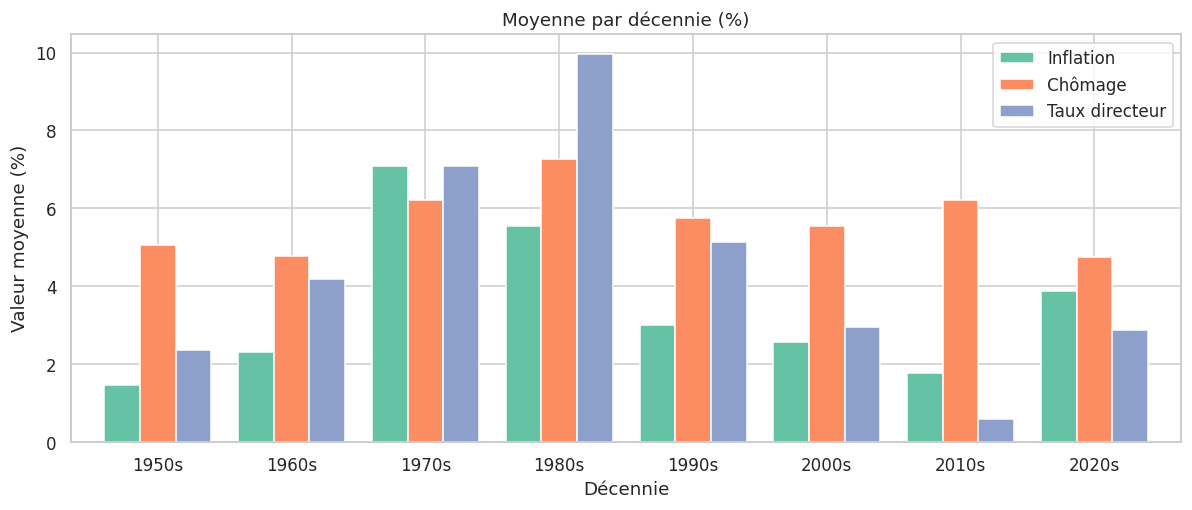

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.8))
par_decennie.rename(columns={"infl": "Inflation", "chom": "Chômage", "taux": "Taux directeur"}).plot.bar(ax=ax, width=0.8)
ax.set_title("Moyenne par décennie (%)")
ax.set_xlabel("Décennie")
ax.set_ylabel("Valeur moyenne (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Lecture.** Les décennies sont très différentes les unes des autres : forte inflation et taux élevés dans les années 1970-1980, puis baisse progressive, taux presque nuls dans les années 2010, remontée de l'inflation dans les années 2020. Une relation apprise sur une décennie n'est pas forcément valable sur la suivante.

### 6.3 Distribution de l'inflation

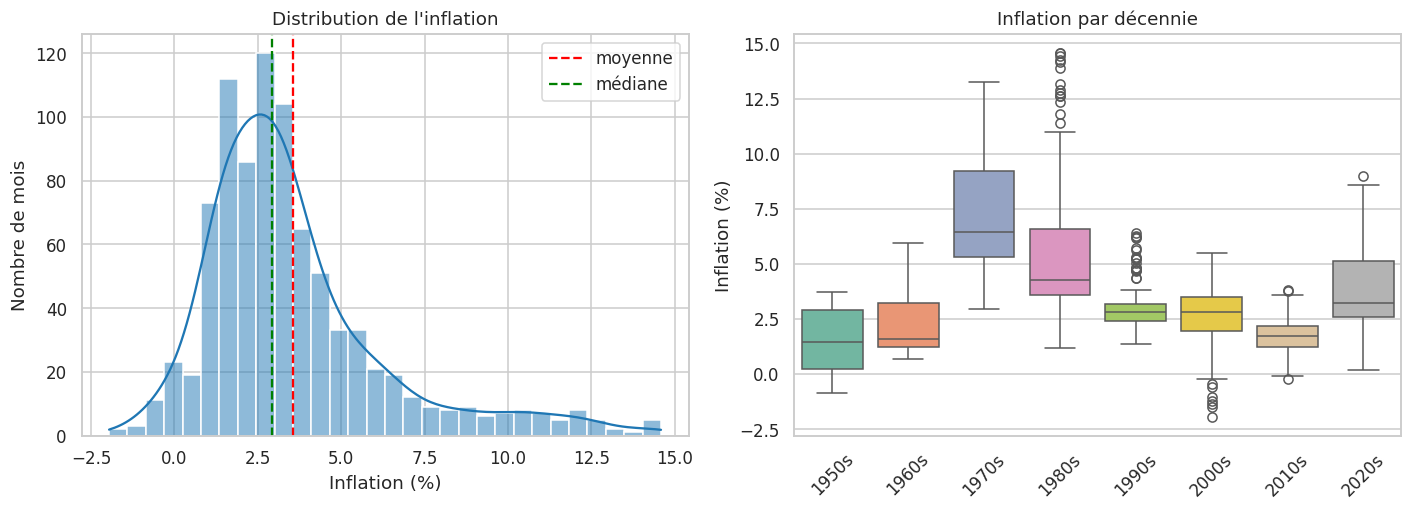

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(df["infl"].dropna(), bins=30, kde=True, ax=axes[0], color="tab:blue")
axes[0].axvline(df["infl"].mean(), color="red", linestyle="--", label="moyenne")
axes[0].axvline(df["infl"].median(), color="green", linestyle="--", label="médiane")
axes[0].set_title("Distribution de l'inflation")
axes[0].set_xlabel("Inflation (%)")
axes[0].set_ylabel("Nombre de mois")
axes[0].legend()

sns.boxplot(data=df.dropna(subset=["infl"]), x="Decennie", y="infl", hue="Decennie", legend=False, ax=axes[1])
axes[1].set_title("Inflation par décennie")
axes[1].set_xlabel("")
axes[1].set_ylabel("Inflation (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Lecture.** La distribution est **asymétrique à droite** : la moyenne (3,6 %) dépasse la médiane (2,9 %) à cause de quelques périodes de forte inflation. Les boîtes à moustaches montrent des écarts énormes entre décennies : très dispersée dans les années 1970-1980, très resserrée dans les années 2010.

### 6.4 Les variables d'aujourd'hui et l'inflation dans 12 mois

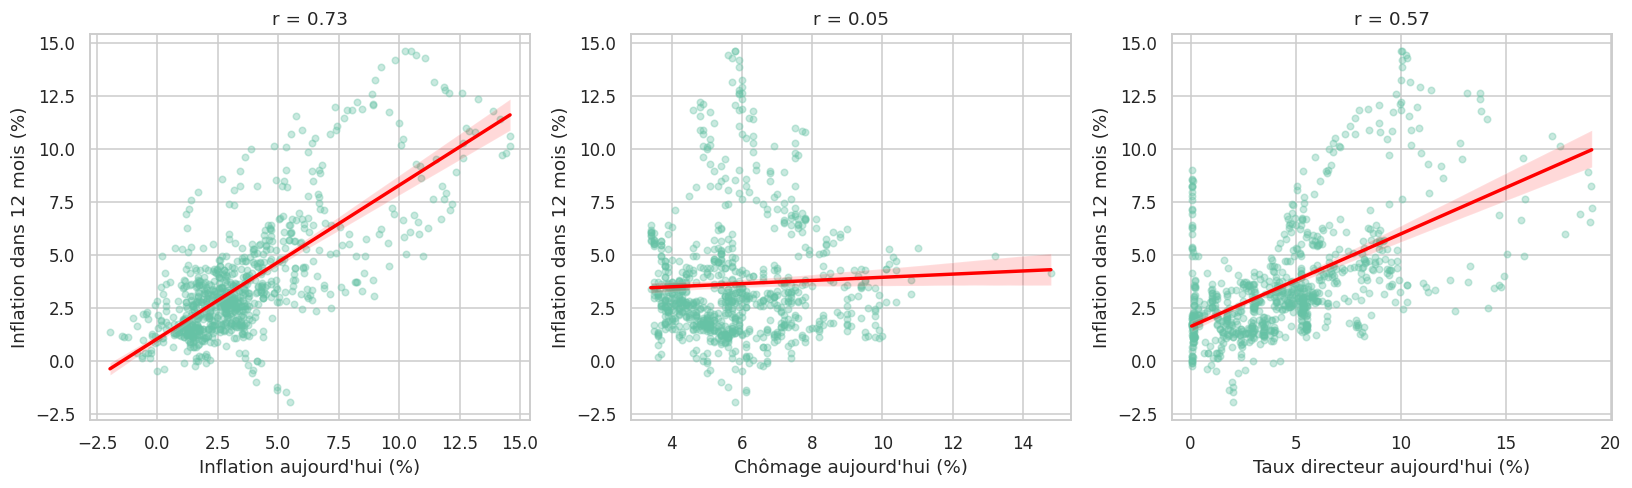

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
paires = [("infl", "Inflation aujourd'hui (%)"),
          ("chom", "Chômage aujourd'hui (%)"),
          ("taux", "Taux directeur aujourd'hui (%)")]
for ax, (col, titre) in zip(axes, paires):
    sub = df[[col, "infl_dans_12m"]].dropna()
    sns.regplot(data=sub, x=col, y="infl_dans_12m", scatter_kws={"alpha": 0.35, "s": 18},
                line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"r = {sub[col].corr(sub['infl_dans_12m']):.2f}")
    ax.set_xlabel(titre)
    ax.set_ylabel("Inflation dans 12 mois (%)")
plt.tight_layout()
plt.show()

**Lecture.** L'inflation d'aujourd'hui est le meilleur indice de l'inflation dans 12 mois (r = 0,73, nuage bien aligné). Pour le taux directeur (r = 0,57), la pente est positive mais le nuage est dispersé. Pour le chômage (r = 0,05), il n'y a pas de pente visible : aucun lien linéaire simple. Attention : ces corrélations en niveau mélangent plusieurs époques, et le lien du taux directeur vient surtout des années 1970-1980.

### 6.5 Corrélation à différents retards

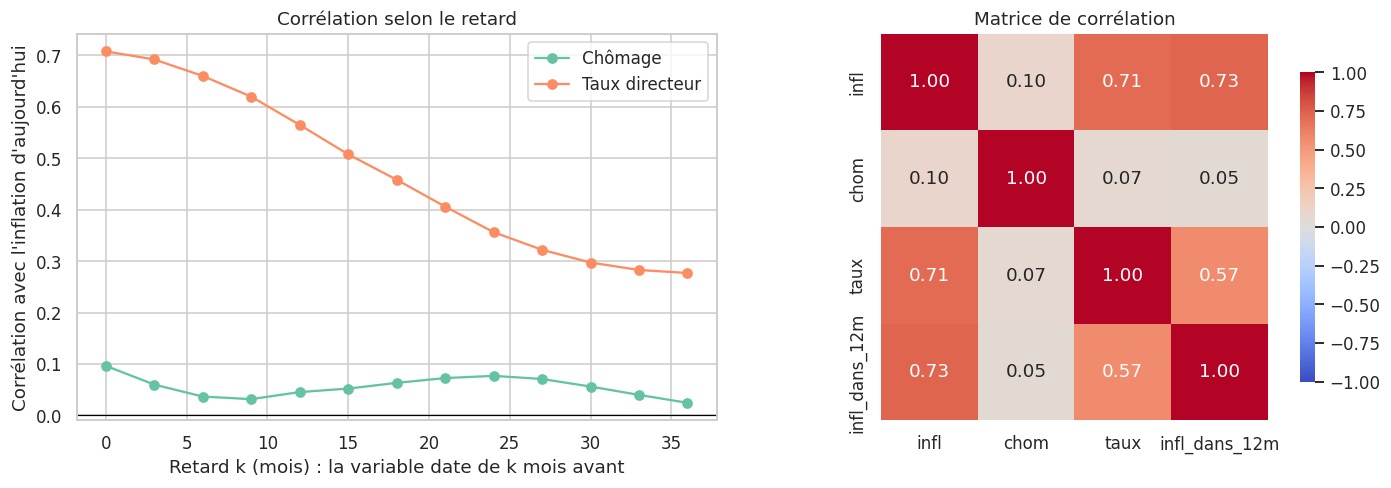

In [25]:
# Corrélation entre l'inflation d'aujourd'hui et le chômage / taux directeur d'il y a k mois
retards = list(range(0, 37, 3))
cc = pd.DataFrame({
    "Chômage": [df["infl"].corr(df["chom"].shift(k)) for k in retards],
    "Taux directeur": [df["infl"].corr(df["taux"].shift(k)) for k in retards],
}, index=retards)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cc.plot(marker="o", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Retard k (mois) : la variable date de k mois avant")
axes[0].set_ylabel("Corrélation avec l'inflation d'aujourd'hui")
axes[0].set_title("Corrélation selon le retard")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Matrice de corrélation")
plt.tight_layout()
plt.show()

**Lecture.** À gauche : la corrélation du chômage avec l'inflation reste proche de zéro quel que soit le retard (entre 0,02 et 0,10). Celle du taux directeur est forte au départ (0,71) et diminue peu à peu avec le retard (0,28 à 36 mois). Elle indique surtout que le taux directeur et l'inflation évoluent ensemble, pas que l'un prédit l'autre : la banque centrale réagit à l'inflation. À droite : la matrice de corrélation résume les liens entre les séries.

## 7. Préparation des données
Règles à respecter :
- **Retards** : pour chaque mois, on garde la valeur actuelle et celles d'il y a 1, 3, 6 et 12 mois, pour les trois séries. Cela donne 15 variables, plus 2 variables de variation sur 12 mois (chômage et taux directeur), soit **17 variables**.
- **Cible** : l'inflation 12 mois plus tard (`décalage de -12`).
- **Pas de mélange aléatoire** : les 120 derniers mois forment le jeu de test.
- **Trou de sécurité de 12 mois** entre l'entraînement et le test. Sans lui, la cible d'un mois d'entraînement tomberait dans la période de test : le modèle verrait par avance une partie du futur.

In [26]:
HORIZON = 12     # on prédit l'inflation 12 mois plus tard
N_TEST = 120     # 10 ans de test
GAP = 12         # trou de sécurité entre entraînement et test

# Construction des variables d'entrée (retards)
X = pd.DataFrame(index=df.index)
for nom, col in [("inflation", "infl"), ("chomage", "chom"), ("taux", "taux")]:
    for k in [0, 1, 3, 6, 12]:
        X[f"{nom}_t" if k == 0 else f"{nom}_t-{k}"] = df[col].shift(k)
X["chomage_var12"] = df["chom"] - df["chom"].shift(12)
X["taux_var12"] = df["taux"] - df["taux"].shift(12)

# Cible : inflation 12 mois plus tard
y = df["infl"].shift(-HORIZON).rename("cible")

# On garde les mois où tout est connu
data = X.join(y).dropna()
X_all, y_all = data[X.columns], data["cible"]

# Groupes de variables (utile pour l'analyse d'importance)
groupes = {
    "Inflation passée": [c for c in X.columns if c.startswith("inflation")],
    "Chômage": [c for c in X.columns if c.startswith("chomage")],
    "Taux directeur": [c for c in X.columns if c.startswith("taux")],
}

# Découpage chronologique avec trou de sécurité
X_train, y_train = X_all.iloc[:-(N_TEST + GAP)], y_all.iloc[:-(N_TEST + GAP)]
X_test, y_test = X_all.iloc[-N_TEST:], y_all.iloc[-N_TEST:]
dates_cible_test = X_test.index + pd.DateOffset(months=HORIZON)

print("Nombre de variables :", X_all.shape[1])
print(f"Entraînement : {len(X_train)} mois, de {X_train.index[0]:%Y-%m} à {X_train.index[-1]:%Y-%m}")
print(f"Test         : {len(X_test)} mois, de {X_test.index[0]:%Y-%m} à {X_test.index[-1]:%Y-%m}"
      f" (inflation prédite de {dates_cible_test[0]:%Y-%m} à {dates_cible_test[-1]:%Y-%m})")

Nombre de variables : 17
Entraînement : 711 mois, de 1955-07 à 2014-09
Test         : 120 mois, de 2015-10 à 2025-09 (inflation prédite de 2016-10 à 2026-09)


## 8. Entraînement et comparaison de modèles

### 8.1 Principe
- **Référence : dernière valeur.** On prédit que l'inflation dans 12 mois sera égale à celle d'aujourd'hui. Tout modèle utile doit faire mieux.
- **Ridge** : régression linéaire avec pénalité, adaptée à des variables corrélées entre elles. Les variables sont standardisées et la force de la pénalité (alpha) est choisie par validation.
- **Gradient boosting** : beaucoup de petits arbres construits l'un après l'autre. Il capte des relations non linéaires.

La comparaison utilise une **validation croisée temporelle** (`TimeSeriesSplit`, avec le même trou de 12 mois) : chaque test se situe toujours après la période d'apprentissage. Métrique : **RMSE** en points de pourcentage (plus petit = meilleur).

In [27]:
class DerniereValeur(BaseEstimator, RegressorMixin):
    """Référence : prédit l'inflation de dans 12 mois = inflation d'aujourd'hui."""
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return X["inflation_t"].values

validation = TimeSeriesSplit(n_splits=5, gap=GAP)

def fabrique_modele(nom):
    if nom == "Dernière valeur (référence)":
        return DerniereValeur()
    if nom == "Ridge":
        pipe = Pipeline([("echelle", StandardScaler()), ("ridge", Ridge())])
        return GridSearchCV(pipe, {"ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]},
                            cv=TimeSeriesSplit(n_splits=3, gap=GAP),
                            scoring="neg_root_mean_squared_error")
    if nom == "Gradient boosting":
        return GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                                         subsample=0.8, random_state=42)

def evaluer(nom, colonnes):
    """RMSE en validation croisée temporelle (entraînement) puis RMSE sur le test."""
    scores = -cross_val_score(fabrique_modele(nom), X_train[colonnes], y_train,
                              cv=validation, scoring="neg_root_mean_squared_error")
    modele = fabrique_modele(nom).fit(X_train[colonnes], y_train)
    pred = modele.predict(X_test[colonnes])
    return {"RMSE validation": scores.mean(), "Écart-type": scores.std(),
            "RMSE test": rmse(y_test, pred), "MAE test": mean_absolute_error(y_test, pred),
            "pred": pred, "modele": modele}

toutes = list(X_all.columns)
resultats = {nom: evaluer(nom, toutes)
             for nom in ["Dernière valeur (référence)", "Ridge", "Gradient boosting"]}

tableau = pd.DataFrame({nom: {k: v for k, v in r.items() if k not in ("pred", "modele")}
                        for nom, r in resultats.items()}).T
tableau = tableau.sort_values("RMSE validation")
print("Meilleur alpha de Ridge :", resultats["Ridge"]["modele"].best_params_["ridge__alpha"])
tableau.round(3)

Meilleur alpha de Ridge : 1000


,RMSE validation,Écart-type,RMSE test,MAE test
Dernière valeur (référence),1.987,0.664,2.356,1.658
Ridge,2.848,1.723,2.381,1.724
Gradient boosting,2.967,1.257,3.612,2.626


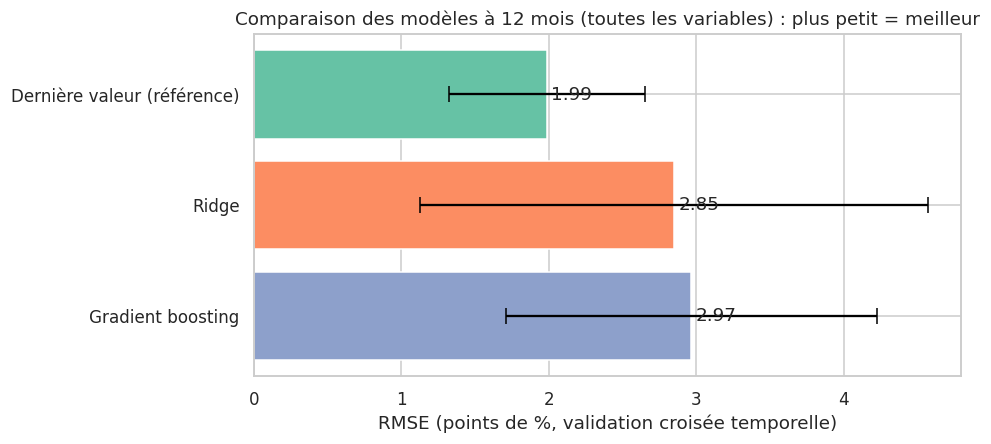

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(tableau.index, tableau["RMSE validation"], xerr=tableau["Écart-type"], capsize=5,
        color=sns.color_palette("Set2", len(tableau)))
ax.invert_yaxis()
for i, v in enumerate(tableau["RMSE validation"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center")
ax.set_xlabel("RMSE (points de %, validation croisée temporelle)")
ax.set_title("Comparaison des modèles à 12 mois (toutes les variables) : plus petit = meilleur")
plt.tight_layout()
plt.show()

**Lecture.** Résultat à première vue surprenant : la référence « dernière valeur » a le **meilleur RMSE en validation** (1,99), devant Ridge (2,85) et le gradient boosting (2,96). Sur le test, Ridge (2,38) fait comme la référence (2,36), et le gradient boosting est le moins bon (3,57). Les écarts-types sont grands (1,7 pour Ridge) : l'incertitude est forte. Explication probable : l'inflation est très persistante, donc difficile à battre avec la simple valeur actuelle, et les modèles apprennent sur des périodes (années 1970-1980) très différentes de la période récente. Le gradient boosting, très flexible, s'adapte trop au passé. Ridge choisit ici une pénalité forte (alpha = 1000), signe que la prudence paye.

### 8.2 Le chômage et le taux directeur aident-ils ? (test direct de la question)
On refait la comparaison en changeant l'ensemble des variables d'entrée :
1. inflation seule ;
2. inflation + chômage ;
3. inflation + taux directeur ;
4. toutes les variables.

Si ajouter une variable fait baisser le RMSE, elle aide à prévoir. Sinon, elle n'apporte rien.

In [29]:
jeux = {
    "Inflation seule": groupes["Inflation passée"],
    "+ chômage": groupes["Inflation passée"] + groupes["Chômage"],
    "+ taux directeur": groupes["Inflation passée"] + groupes["Taux directeur"],
    "Toutes les variables": toutes,
}

lignes = []
for nom_jeu, cols in jeux.items():
    for nom_modele in ["Ridge", "Gradient boosting"]:
        r = evaluer(nom_modele, cols)
        lignes.append({"Variables": nom_jeu, "Modèle": nom_modele,
                       "RMSE validation": r["RMSE validation"], "RMSE test": r["RMSE test"]})
ablation = pd.DataFrame(lignes)
rmse_ref_test = resultats["Dernière valeur (référence)"]["RMSE test"]

print(f"Référence (dernière valeur) : RMSE test = {rmse_ref_test:.3f}\n")
ablation.pivot(index="Variables", columns="Modèle", values=["RMSE validation", "RMSE test"]).reindex(list(jeux)).round(3)

Référence (dernière valeur) : RMSE test = 2.356



RMSE validation                RMSE test       
Modèle               Gradient boosting  Ridge Gradient boosting  Ridge
Variables                                                             
Inflation seule                  2.630  2.437             3.144  2.030
+ chômage                        2.544  2.519             3.572  2.360
+ taux directeur                 2.567  2.930             3.583  2.455
Toutes les variables             2.967  2.848             3.612  2.381

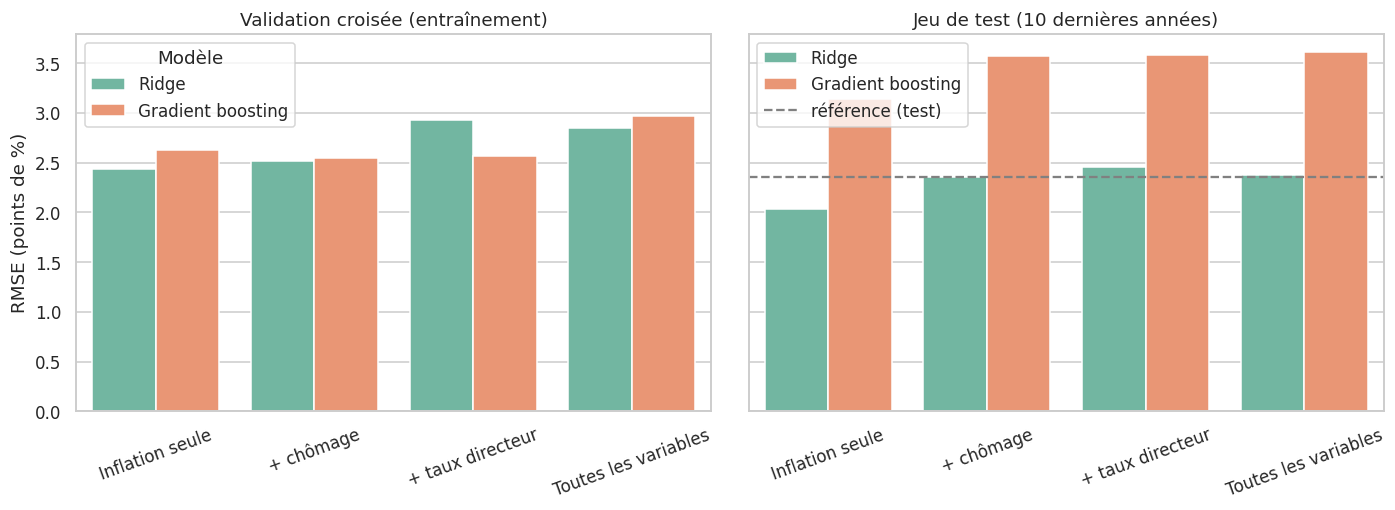

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, colonne, titre in [(axes[0], "RMSE validation", "Validation croisée (entraînement)"),
                           (axes[1], "RMSE test", "Jeu de test (10 dernières années)")]:
    sns.barplot(data=ablation, x="Variables", y=colonne, hue="Modèle", order=list(jeux), ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("")
    ax.set_ylabel("RMSE (points de %)")
    ax.tick_params(axis="x", rotation=20)
axes[1].axhline(rmse_ref_test, color="grey", linestyle="--", label="référence (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lecture.** C'est le test direct de la question.
- **Ridge** : l'inflation passée seule donne le meilleur RMSE test (2,03), meilleur même que la référence (2,36). Ajouter le chômage (2,36), le taux directeur (2,46) ou les deux (2,38) fait **monter** l'erreur. La validation va dans le même sens (2,44 pour l'inflation seule, contre 2,52, 2,93 et 2,85).
- **Gradient boosting** : en validation, ajouter le chômage ou le taux directeur baisse un peu le RMSE (2,63 vers 2,55 et 2,57), mais cet écart est petit comparé aux écarts-types (environ 1,3). Sur le test, l'erreur monte au contraire (3,17 vers 3,6).

**Conclusion partielle :** on ne trouve pas de preuve que le chômage et le taux directeur aident à prévoir l'inflation à 12 mois. Ils semblent plutôt ajouter du bruit.

## 9. Évaluation finale sur le jeu de test
Les modèles (toutes variables) ont été entraînés sur l'entraînement uniquement. Voici leurs prévisions sur les 10 dernières années, comparées à la réalité.

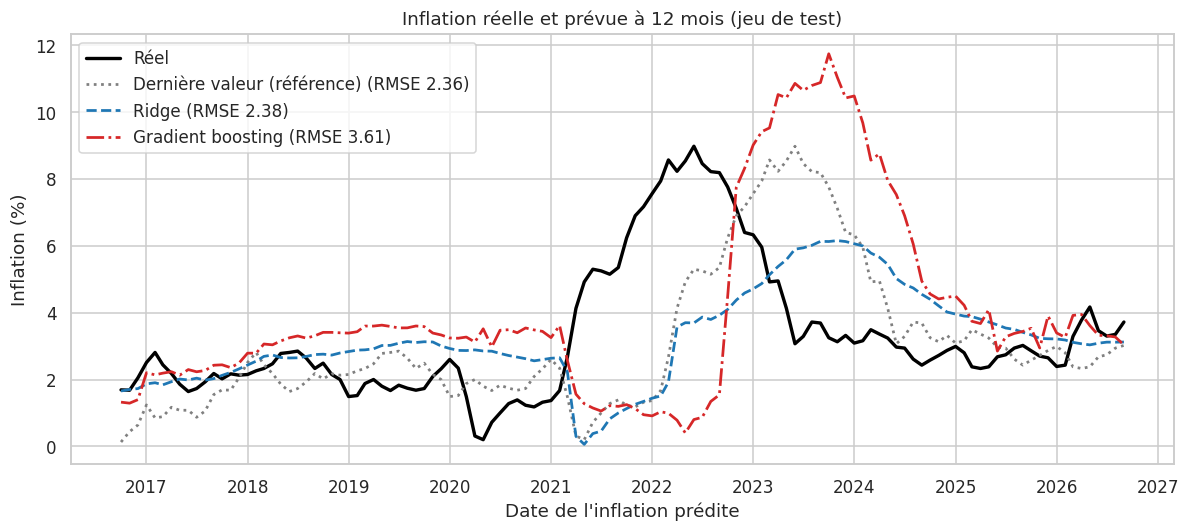

In [31]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(dates_cible_test, y_test.values, color="black", linewidth=2.2, label="Réel")
styles = {"Dernière valeur (référence)": ("grey", ":"), "Ridge": ("tab:blue", "--"), "Gradient boosting": ("tab:red", "-.")}
for nom, (couleur, style) in styles.items():
    ax.plot(dates_cible_test, resultats[nom]["pred"], color=couleur, linestyle=style, linewidth=1.8,
            label=f"{nom} (RMSE {resultats[nom]['RMSE test']:.2f})")
ax.set_title("Inflation réelle et prévue à 12 mois (jeu de test)")
ax.set_xlabel("Date de l'inflation prédite")
ax.set_ylabel("Inflation (%)")
ax.legend()
plt.tight_layout()
plt.show()

In [32]:
# Où se concentrent les erreurs ? RMSE par sous-période
erreurs = pd.DataFrame({nom: y_test.values - r["pred"] for nom, r in resultats.items()}, index=dates_cible_test)
annee = erreurs.index.year
phase = np.where(annee < 2020, "1) avant 2020", np.where(annee <= 2023, "2) 2020-2023", "3) après 2023"))
rmse_phase = erreurs.pow(2).groupby(phase).mean().pow(0.5)
rmse_phase["Nombre de mois"] = pd.Series(phase).value_counts().sort_index().values
rmse_phase.round(2)

,Dernière valeur (référence),Ridge,Gradient boosting,Nombre de mois
1) avant 2020,0.87,0.74,1.09,39
2) 2020-2023,3.53,3.50,5.13,48
3) après 2023,1.09,1.47,2.78,33


**Lecture.** Aucun modèle n'a vu venir la montée de l'inflation de 2021-2022 : tous les trois sont en retard sur la courbe réelle. Le tableau confirme que presque toute l'erreur vient de cette période : RMSE de 0,74 à 1,04 avant 2020, de 3,5 à 5,1 entre 2020 et 2023, de 1,09 à 2,73 après 2023. Le gradient boosting est le moins bon dans chaque période. Ridge fait un peu mieux que la référence avant 2020 (0,74 contre 0,87), mais moins bien après 2023 (1,47 contre 1,09). Un RMSE global de 2,4 points est donc surtout le reflet d'un choc imprévisible.

## 10. Importance des variables
Trois façons complémentaires de répondre à « quelles variables comptent ? » :
1. les **coefficients de Ridge** (sur variables standardisées : comparables entre eux) ;
2. l'**importance du gradient boosting** (part de la réduction d'erreur due à chaque variable) ;
3. l'**importance par permutation, par groupe** : on mélange au hasard toutes les colonnes d'un groupe (par exemple tout le chômage) sur le jeu de test et on mesure de combien le RMSE augmente. Plus il augmente, plus le groupe est utile au modèle.

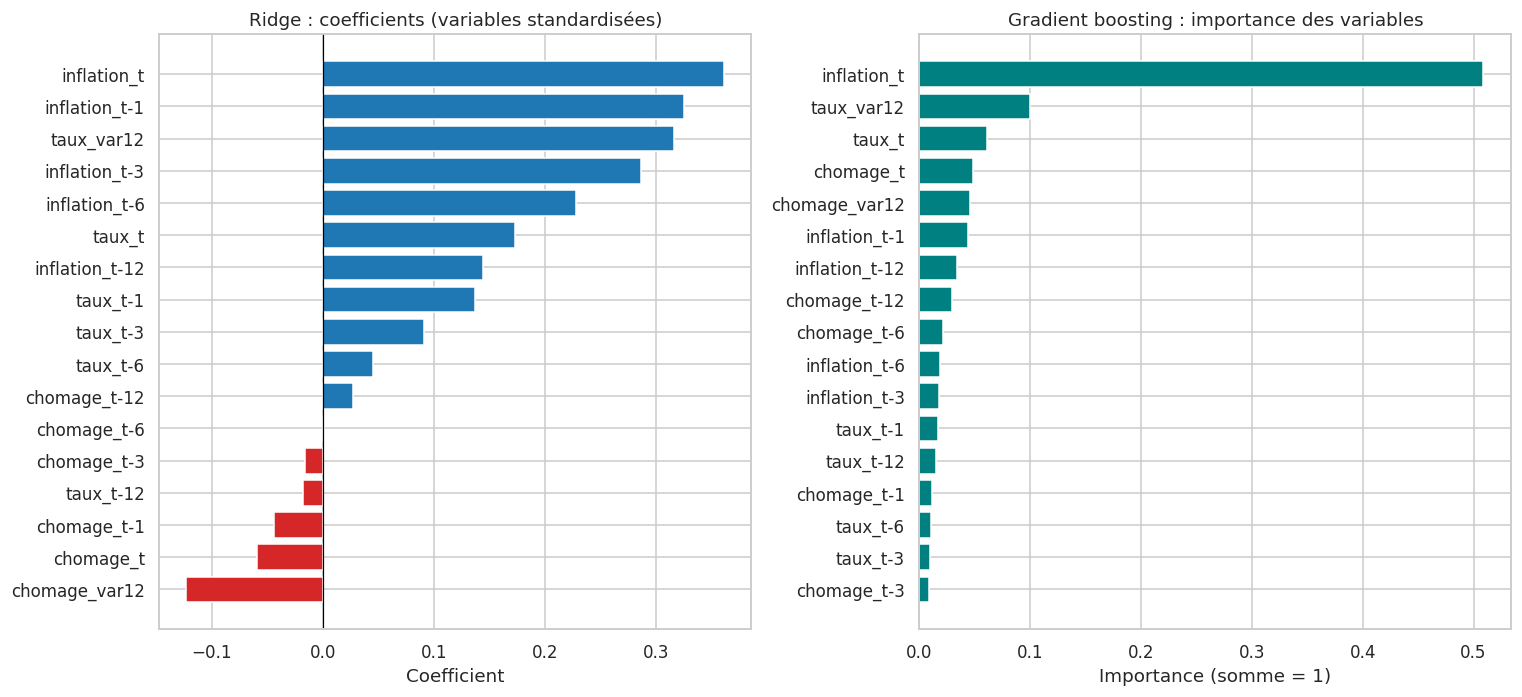

In [33]:
ridge = resultats["Ridge"]["modele"].best_estimator_
gb = resultats["Gradient boosting"]["modele"]

coefs = pd.Series(ridge.named_steps["ridge"].coef_, index=toutes).sort_values()
imp_gb = pd.Series(gb.feature_importances_, index=toutes).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(coefs.index, coefs.values, color=["tab:red" if v < 0 else "tab:blue" for v in coefs.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Ridge : coefficients (variables standardisées)")
axes[0].set_xlabel("Coefficient")

axes[1].barh(imp_gb.index, imp_gb.values, color="teal")
axes[1].set_title("Gradient boosting : importance des variables")
axes[1].set_xlabel("Importance (somme = 1)")
plt.tight_layout()
plt.show()

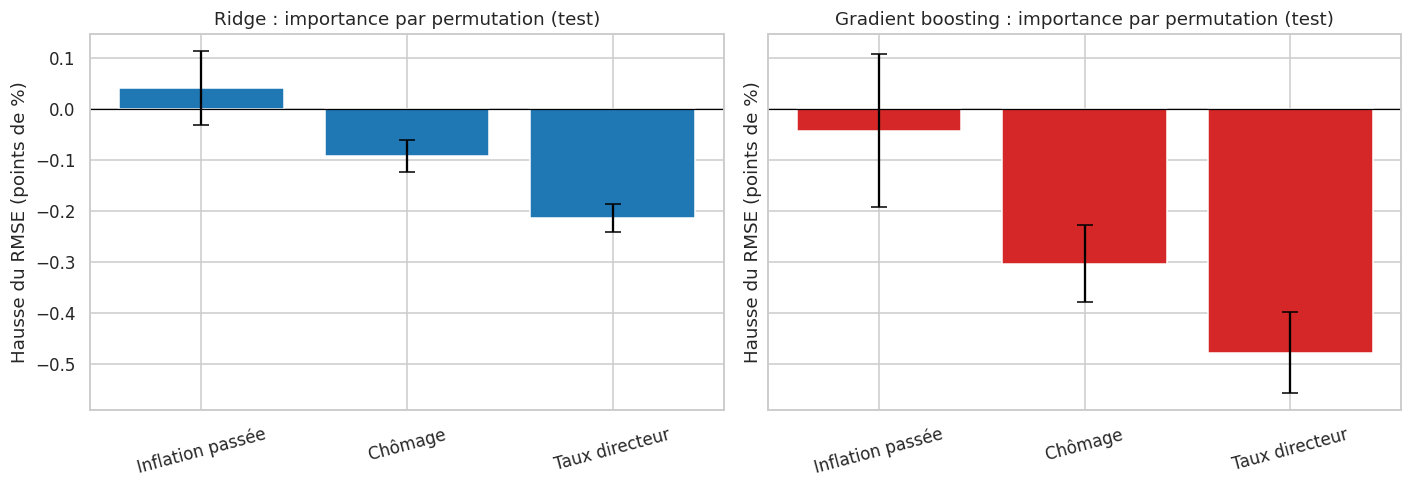

Ridge :
                  hausse du RMSE  écart-type
Inflation passée           0.041       0.073
Chômage                   -0.092       0.032
Taux directeur            -0.213       0.028

Gradient boosting :
                  hausse du RMSE  écart-type
Inflation passée          -0.043       0.150
Chômage                   -0.303       0.076
Taux directeur            -0.479       0.079


In [34]:
def importance_groupes(modele, X, y, groupes, n_rep=30, graine=42):
    """Hausse du RMSE quand on mélange toutes les colonnes d'un groupe (jeu de test)."""
    rng = np.random.default_rng(graine)
    ref = rmse(y, modele.predict(X))
    sortie = {}
    for nom, cols in groupes.items():
        hausses = []
        for _ in range(n_rep):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            hausses.append(rmse(y, modele.predict(Xp)) - ref)
        sortie[nom] = (np.mean(hausses), np.std(hausses))
    return pd.DataFrame(sortie, index=["hausse du RMSE", "écart-type"]).T

perm_ridge = importance_groupes(resultats["Ridge"]["modele"], X_test, y_test, groupes)
perm_gb = importance_groupes(gb, X_test, y_test, groupes)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, tab, titre, couleur in [(axes[0], perm_ridge, "Ridge", "tab:blue"), (axes[1], perm_gb, "Gradient boosting", "tab:red")]:
    ax.bar(tab.index, tab["hausse du RMSE"], yerr=tab["écart-type"], capsize=5, color=couleur)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{titre} : importance par permutation (test)")
    ax.set_ylabel("Hausse du RMSE (points de %)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("Ridge :"); print(perm_ridge.round(3))
print("\nGradient boosting :"); print(perm_gb.round(3))

**Lecture.**
- **Ridge** : les plus gros coefficients sont ceux de l'inflation passée (surtout les retards de 0 à 6 mois). Parmi les autres variables, la variation du taux directeur sur 12 mois est positive (+0,32) : quand la banque centrale a monté ses taux, l'inflation est plus haute dans les données, ce qui reflète surtout sa réaction à l'inflation. La variation du chômage est négative (-0,12), dans le sens attendu (chômage qui monte, inflation qui baisse), mais petite. Attention : les variables sont corrélées entre elles, donc les coefficients individuels sont à lire avec prudence.
- **Gradient boosting** : l'inflation actuelle pèse environ la moitié de l'importance (51 %), suivie de la variation du taux directeur (10 %), du taux directeur (6 %) et du chômage (5 %). Cette mesure est calculée sur l'entraînement.
- **Permutation sur le test** : mélanger le chômage ou le taux directeur **fait baisser** le RMSE (barres négatives). Cela veut dire que ce que les modèles ont appris de ces variables sur 1955-2014 n'est pas valable sur 2016-2026 et leur fait plutôt du tort. Pour l'inflation passée, l'effet est proche de zéro (l'écart-type est de l'ordre de la valeur) : sur cette période de test, dominée par le choc de 2021-2022, même elle aide peu.

**En résumé :** pendant l'apprentissage, l'inflation passée domine, puis le taux directeur, puis le chômage. Mais sur des données jamais vues, ni le chômage ni le taux directeur ne rendent service. L'importance mesure ce que le modèle utilise, pas une cause.

## 11. Prévision pour le prochain horizon de 12 mois

In [35]:
# Dernier mois où toutes les variables d'entrée sont connues (l'inflation d'octobre 2026 n'est pas encore publiée)
derniere = X.dropna().iloc[[-1]]
date_origine = derniere.index[0]
date_cible = date_origine + pd.DateOffset(months=HORIZON)

# Modèles réentraînés sur toutes les données où la cible est connue
prevus = {}
for nom in ["Dernière valeur (référence)", "Ridge", "Gradient boosting"]:
    modele_final = fabrique_modele(nom).fit(X_all, y_all)
    prevus[nom] = modele_final.predict(derniere)[0]

meilleur_nom = tableau.index[0]
print(f"Dernière observation utilisée : {date_origine:%Y-%m} (inflation = {derniere['inflation_t'].iloc[0]:.2f} %)")
print(f"Inflation prévue pour {date_cible:%Y-%m} :")
for nom, v in prevus.items():
    print(f"  - {nom:30s} {v:5.2f} %")
print(f"\nModèle retenu (meilleur RMSE en validation) : {meilleur_nom}")
print(f"Ordre de grandeur de l'incertitude : ± {resultats[meilleur_nom]['RMSE test']:.1f} point (RMSE test)")

Dernière observation utilisée : 2026-09 (inflation = 3.72 %)
Inflation prévue pour 2027-09 :
  - Dernière valeur (référence)     3.72 %
  - Ridge                           3.33 %
  - Gradient boosting               2.82 %

Modèle retenu (meilleur RMSE en validation) : Dernière valeur (référence)
Ordre de grandeur de l'incertitude : ± 2.4 point (RMSE test)


**Lecture.** Dans notre exécution, le modèle retenu par la validation est la **référence** (dernière valeur) : elle prévoit 3,72 % pour septembre 2027. Ridge donne 3,33 % et le gradient boosting 2,77 %. Les trois prévisions sont assez différentes et l'erreur typique du test est d'environ 2,4 points : cette prévision est **très incertaine** et doit être présentée comme un ordre de grandeur, pas comme une certitude.

## 12. Limites : biais d'anticipation (*look-ahead bias*) et autres risques
**Ce qu'il faut signaler dans le rapport.**

1. **Révisions des données.** Les séries économiques sont révisées après leur publication. L'indice des prix et le chômage de la série FRED (CPIAUCSL, UNRATE) sont désaisonnalisés : leurs facteurs saisonniers sont réestimés chaque année, ce qui modifie les valeurs passées. Le taux directeur, lui, n'est pas révisé. Les données de notre fichier sont celles d'**aujourd'hui**, pas celles qu'un prévisionniste aurait eues à l'époque. C'est un **biais d'anticipation** : le modèle apprend et est testé sur des valeurs « propres » que personne ne connaissait en temps réel. Pour le corriger, il faudrait utiliser des **données en temps réel** (les « millésimes » d'origine, disponibles sur ALFRED, la base d'archives de FRED).
2. **Délai de publication.** L'inflation du mois *t* est publiée environ à la mi-mois suivant, et le chômage début du mois suivant. Notre modèle suppose qu'on connaît ces valeurs dès la fin du mois *t*. En pratique, l'information est un peu plus ancienne.
3. **Choix faits en regardant les données.** Le choix des retards, de la période de test et des hyperparamètres a été fait en connaissant l'histoire. Les résultats sont donc plutôt **optimistes**.
4. **Changements de régime.** La relation entre chômage, taux et inflation n'est pas stable (années 1970, années 2010, choc de 2021-2022). Un modèle appris sur le passé peut échouer au moment précis d'un choc nouveau.
5. **Corrélation n'est pas causalité.** Un résultat d'importance montre ce qui aide à *prédire*, pas ce qui *cause* l'inflation.

**Conséquence.** Les erreurs mesurées ici (RMSE) sont probablement des **minimums** : en conditions réelles, elles seraient plus élevées.

## 13. Synthèse et questions

### Ce qu'il faut retenir
1. **Type de problème** : régression supervisée sur série temporelle, horizon 12 mois.
2. **Démarche** : nettoyer, explorer, construire des retards, découper dans l'ordre du temps avec un trou de sécurité, comparer à une référence simple, valider par validation croisée temporelle, évaluer une seule fois sur le test.
3. **Réponse à la question** : **non, pas de façon fiable**. Ajouter le chômage et/ou le taux directeur n'améliore pas la prévision à 12 mois : avec Ridge, le RMSE test est plus faible avec l'inflation passée seule (2,03) qu'avec toutes les variables (2,38). Le taux directeur est corrélé à l'inflation future (r = 0,57), mais ce lien vient surtout des années 1970-1980 : depuis 1990, il tombe à 0,10. Le chômage n'a presque aucun lien linéaire avec l'inflation future.
4. **Limites** : biais d'anticipation (données révisées, délais de publication), changements de régime, résultats probablement optimistes.

### Questions
1. Pourquoi faut-il un trou de 12 mois entre l'entraînement et le test pour un horizon de 12 mois ?
2. Pourquoi la référence « dernière valeur » est-elle difficile à battre pour l'inflation ?
3. Changez `N_TEST` (60, 180). Les conclusions sur l'utilité du chômage et du taux directeur changent-elles ?
4. Changez `HORIZON` (3, 6, 24). L'erreur augmente-t-elle avec l'horizon ? Pourquoi ?
5. Quelles autres variables pourraient aider (prix du pétrole, masse monétaire, anticipations d'inflation) et pourquoi ?